In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', 'TCGA', 'PANCAN')
pth_bed = os.path.join(pth_data, 'TCGA')
pth_out = os.path.join(pth, 'figures', 'TCGA')

In [3]:
effect_type_dict = {
    "3'UTR"             : 'Noncoding',
    'Intron'            : 'Noncoding',
    'Frame_Shift_Del'   : 'Coding',
    'Frame_Shift_Ins'   : 'Coding',
    'In_Frame_Del'      : 'Coding',
    'Missense_Mutation' : 'Coding',
    'Nonsense_Mutation' : 'Coding'}

In [4]:
# select POU5F1 mutations (non-silent)
df = pd.read_csv(os.path.join(pth_in, 'mc3.v0.2.8.PUBLIC.xena'), sep = '\t')
df = df.loc[(df.gene == 'POU5F1') & (df.effect != 'Silent')].copy()
df['chr'] = 'chr' + df.chr.copy(); df = df.sort_values('start')

In [5]:
# load disease types
fn = os.path.join(pth_in, 'TCGA_phenotype_denseDataOnlyDownload.tsv')
disease = (pd.read_csv(fn, sep = '\t', index_col = 0)
    ._primary_disease.str.title().str.replace('&', 'and'))

In [6]:
# map disease, effect types
df['_primary_disease'] = df['sample'].map(disease.to_dict())
df['effect_type'] = df.effect.map(effect_type_dict)

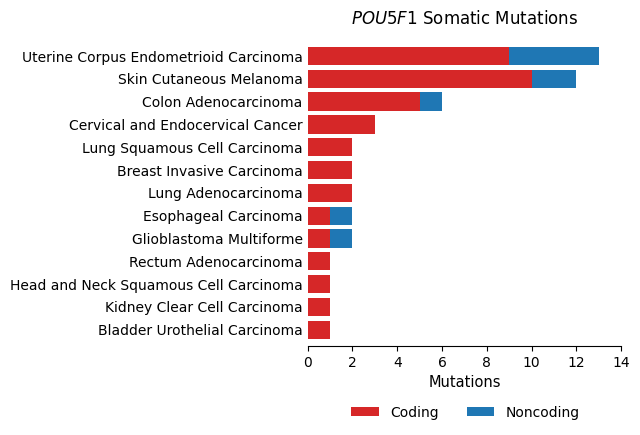

In [7]:
# plot crosstab (barh)
fig, ax = plt.subplots(1, 1, figsize = (6.5, 4.5))
c = {'Coding' : 'tab:red', 'Noncoding' : 'tab:blue'}
df_plt = pd.crosstab(df._primary_disease, df.effect_type)
df_plt = df_plt.loc[df_plt.sum(axis = 1).sort_values().index]
left = pd.Series(0, index = df_plt.index)

for col in df_plt.columns:
    ax.barh(
        df_plt.index,
        df_plt[col],
        left = left,
        label = col,
        color = c[col])
    left += df_plt[col]

ax.set_xlabel('Mutations', size = 10.5)
ax.set_xlim(0, 14)
ax.tick_params('y', size = 0)
ax.set_ylim(ax.get_ylim()[0] + .33)
ax.set_title(r'$POU5F1$ Somatic Mutations', size = 12)
ax.legend(bbox_to_anchor = (.9075, -.15),
          ncol = 2, frameon = False)

for loc in ('top', 'right', 'left'):
    ax.spines[loc].set_visible(False)

fig.tight_layout()
fn = os.path.join(pth_out, 'mutations.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [ ]:
# save locations (bedGraph)
w, cols = 25, ['chr', 'start']
df_out = df[cols].copy()
df_out['start'] = ((df_out.start - 1) // w) * w
df_out = (df_out.groupby(cols, observed = True)
          .size().reset_index())
df_out['end'] = df_out.start + w
df_out = df_out[[*cols, 'end', 0]]
fn = os.path.join(pth_bed, 'TCGA.mc3.bedGraph')
df_out.to_csv(fn, sep = '\t', header = False, index = False)